# Alpha-synuclein: comparing tICA features and testing an exploratory MSM

Compare Cα pair distances, local writhe, and periodic Cα pseudo-dihedrals on the same 5,555-frame trajectory. Inspect projections, structural observables, representative conformations, lag dependence, and validation on separate trajectory halves before constructing a small MSM.

**Main finding:** apparent slow modes are not stable across trajectory halves. A small CK discrepancy alone does not establish a reliable metastable model. The final two-state MSM is exploratory.

The coordinate interval is **inferred** from the supplied total duration of 200 μs: approximately 36 ns per saved frame. It has not been independently verified against simulation metadata. All analyses use the same saved frames.

The downloadable cache contains Cα coordinates (Å), writhe features, and segment definitions. Distances and sine/cosine pseudo-dihedral features are recalculated below. Original PDB and DCD files are in `data/asyn` in the class repository. Writhe features were calculated with `writhe-tools==0.0.0.0.30`, segment length 3, excluding shared endpoints. This cache avoids requiring that package to reproduce the analysis.

In [1]:
import sys, subprocess, importlib.util
if importlib.util.find_spec("MDAnalysis") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "MDAnalysis"])
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from MDAnalysis.lib.distances import calc_dihedrals
from pathlib import Path
from urllib.request import urlretrieve

plt.rcParams.update({"font.size": 11, "figure.dpi": 130})
data_dir = Path("asyn_analysis_outputs")
data_dir.mkdir(exist_ok=True)
cache = data_dir / "asyn_ca_writhe_features.npz"
local_cache = Path("../data/asyn/asyn_ca_writhe_features.npz")
if local_cache.exists():
    cache = local_cache
elif not cache.exists():
    urlretrieve("https://raw.githubusercontent.com/paulrobustelli/CSMP_150_2026/main/data/asyn/asyn_ca_writhe_features.npz", cache)
wr = np.load(cache)
xyz = wr["xyz"]
assert xyz.shape == (5555, 20, 3)
dt_us = 200 / len(xyz)  # Inferred interval; not calibrated from DCD metadata.
lag = 28
print(f"{len(xyz):,} frames; inferred spacing {dt_us*1000:.2f} ns; lag {lag*dt_us:.3f} μs")

5,555 frames; inferred spacing 36.00 ns; lag 1.008 μs


/Users/paulrobustelli/Documents/Codex/2026-11-11/referenced-chatgpt-conversation-this-is-an/work/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Represent the same structures three ways
- **Distances:** the 190 unique Cα pairs, in Å.
- **Writhe:** 122 unique pairs of local segments, computed with `writhe-tools` 0.0.0.30 using segment length 3. Shared-endpoint pairs are excluded. The cached features avoid repeating the package calculation here.
- **Pseudo-dihedrals:** 17 torsion angles, each defined by four consecutive Cα atoms. Both sine and cosine are retained, giving 34 features and avoiding the discontinuity at ±π.

PCA uses each representation in its native units, without per-feature standardization. Variance magnitudes across representations therefore should not be compared directly.

In [2]:
i, j = np.triu_indices(xyz.shape[1], k=1)
distances = np.linalg.norm(xyz[:, i] - xyz[:, j], axis=2)
# Calculate the signed torsion for each consecutive quartet in every frame.
quartets = [np.ascontiguousarray(xyz[:, k:k+17].reshape(-1, 3), dtype=np.float64) for k in range(4)]
angles = calc_dihedrals(*quartets).reshape(len(xyz), 17)
periodic = np.concatenate([np.sin(angles), np.cos(angles)], axis=1)
features = {'Distances': distances, 'Writhe': wr['writhe_features'], 'Cα torsions (sin/cos)': periodic}
# Equal-weight Cα radius of gyration, used as an independent structural annotation.
rg = np.sqrt(np.mean(np.sum((xyz - xyz.mean(axis=1, keepdims=True))**2, axis=2), axis=1))
for name, F in features.items():
    assert np.isfinite(F).all()
    print(name, F.shape)


Distances (5555, 190)
Writhe (5555, 122)
Cα torsions (sin/cos) (5555, 34)


## 2. PCA and reversible tICA
For tICA we center both ends of each lagged pair with their pooled mean, then estimate symmetric matrices:

$$C_0=\frac{X_c^TX_c+Y_c^TY_c}{2n},\qquad C_\tau=\frac{X_c^TY_c+Y_c^TX_c}{2n}.$$

Solve $C_\tau w_i=\lambda_i C_0w_i$ in the retained covariance subspace. Directions with covariance eigenvalues below $10^{-8}$ times the largest are discarded. Projections are normalized to unit variance under this paired estimator.

This is an exploratory reversible estimate. Held-out validation and lag sensitivity are still needed before interpreting the inferred slow processes quantitatively.

In [3]:
def analyze(F):
    F = np.asarray(F, dtype=np.float64)
    centered = F - F.mean(axis=0)
    pc_var, pc_vec = eigh(centered.T @ centered / len(F))
    pc_order = np.argsort(pc_var)[::-1]
    pc = centered @ pc_vec[:, pc_order[:2]]
    X, Y = F[:-lag], F[lag:]
    mean = (X.mean(axis=0) + Y.mean(axis=0)) / 2
    X, Y = X - mean, Y - mean
    C0 = (X.T @ X + Y.T @ Y) / (2 * len(X))
    Ct = (X.T @ Y + Y.T @ X) / (2 * len(X))
    d, V = eigh(C0)
    keep = d > d.max() * 1e-8
    whitening = V[:, keep] / np.sqrt(d[keep])
    vals, vec = eigh(whitening.T @ Ct @ whitening)
    order = np.argsort(vals)[::-1]
    vals, weights = vals[order], whitening @ vec[:, order]
    assert np.allclose(weights.T @ C0 @ weights, np.eye(sum(keep)), atol=1e-6)
    assert np.max(np.abs(vals)) < 1 + 1e-8
    return {'pc': pc, 'tic': (F-mean) @ weights[:, :2], 'eigenvalues': vals,
            'rank': int(sum(keep)), 'pca_fraction': pc_var[pc_order[:2]] / pc_var.sum()}
results = {name: analyze(F) for name, F in features.items()}
for name, r in results.items():
    lam = r['eigenvalues'][:2]
    times = np.where((lam > 0) & (lam < 1), -lag*dt_us/np.log(lam), np.nan)
    print(f"{name}: retained rank {r['rank']}; λ = {lam.round(4)}; implied times (μs) = {times.round(3)}")


Distances: retained rank 190; λ = [0.8367 0.4464]; implied times (μs) = [5.655 1.25 ]
Writhe: retained rank 122; λ = [0.8697 0.5128]; implied times (μs) = [7.223 1.509]
Cα torsions (sin/cos): retained rank 34; λ = [0.5489 0.433 ]; implied times (μs) = [1.68  1.204]


## 3. Compare projections
Each point is one saved structure, colored by its Cα radius of gyration. The left column shows PCA; the right shows tICA. Axis signs are arbitrary. These scatter plots reveal structural organization, but do not by themselves demonstrate slow dynamics.

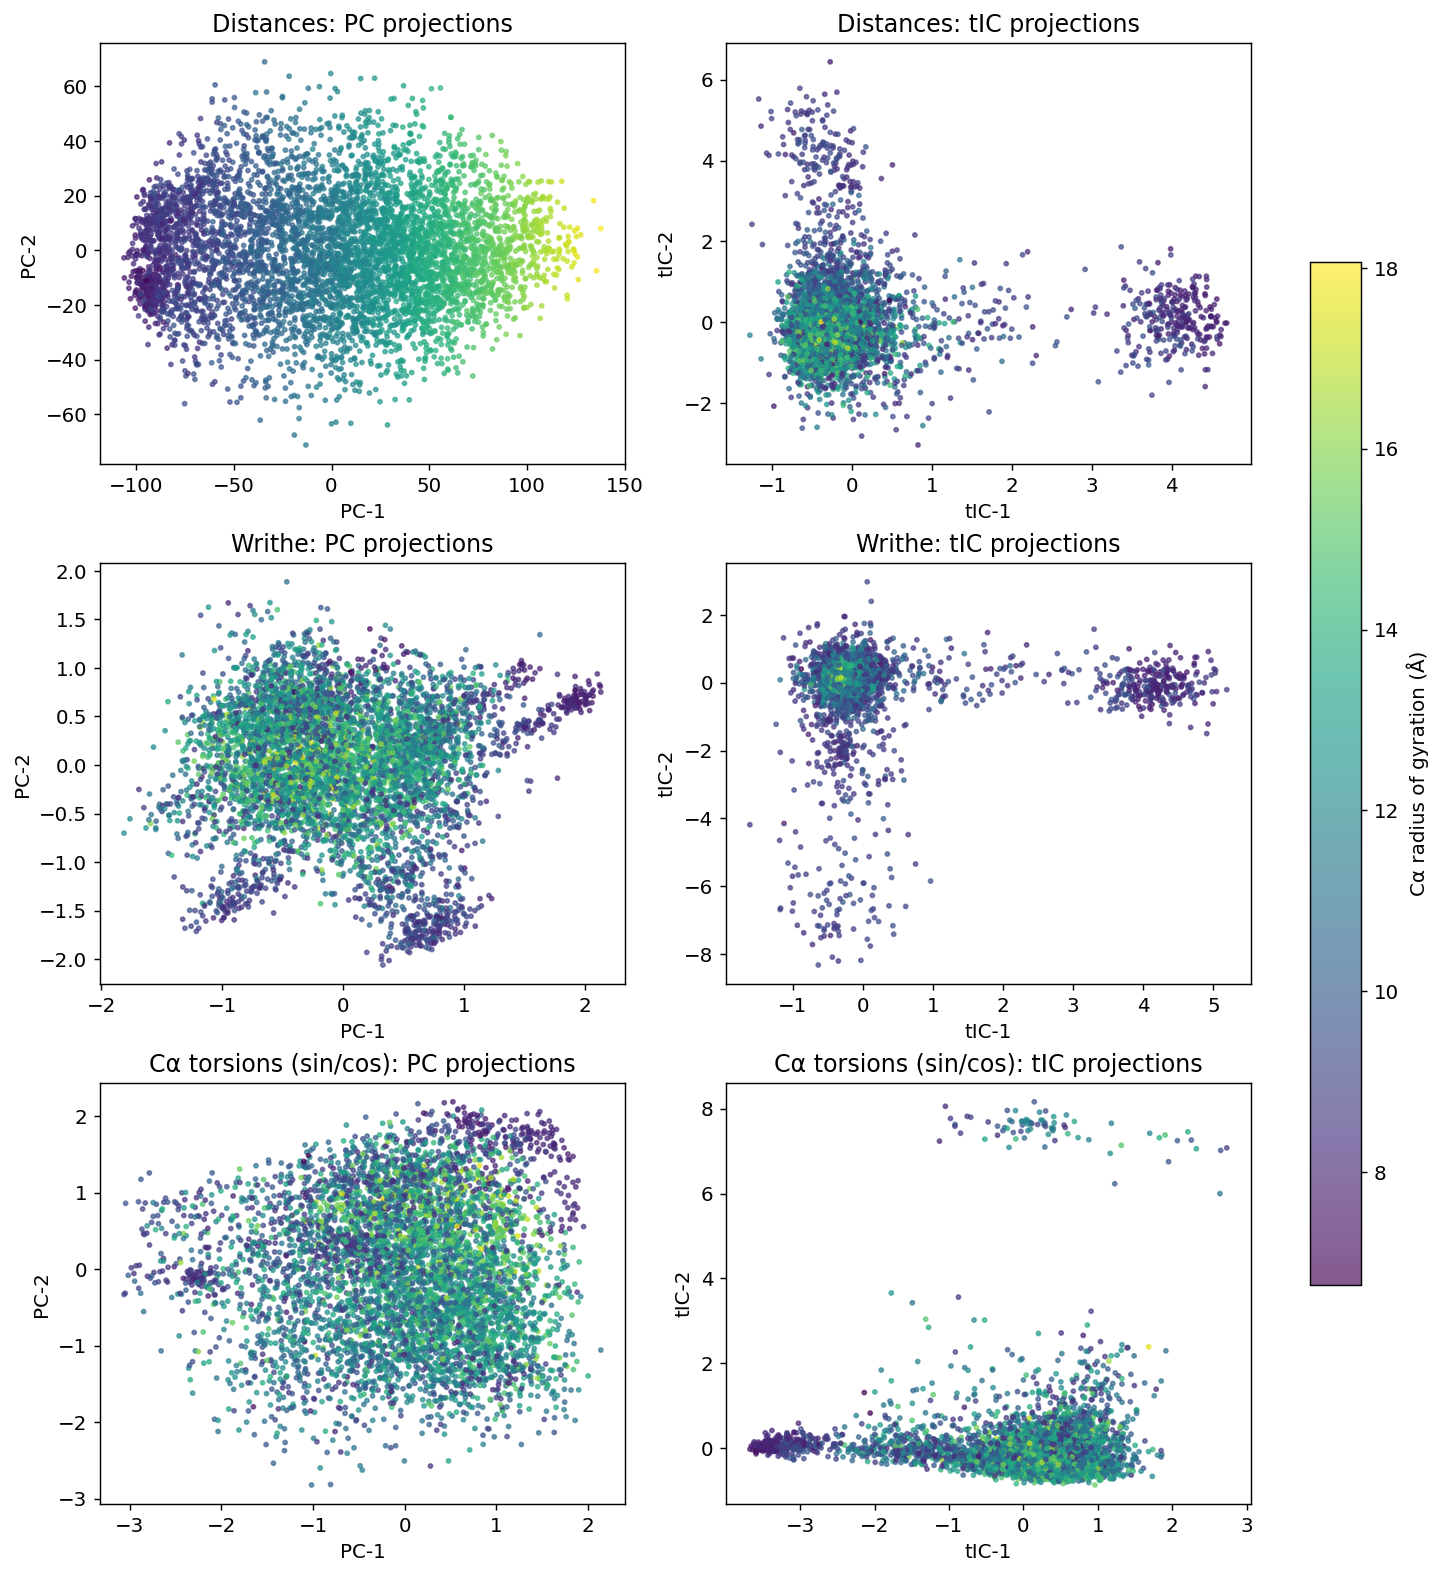

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(11, 12), constrained_layout=True)
for row, (name, r) in enumerate(results.items()):
    for col, (key, label) in enumerate([('pc', 'PC'), ('tic', 'tIC')]):
        ax = axes[row, col]
        q = r[key]
        sc = ax.scatter(q[:,0], q[:,1], c=rg, s=5, cmap='viridis', alpha=0.65,
                        vmin=rg.min(), vmax=rg.max(), rasterized=True)
        ax.set(xlabel=f'{label}-1', ylabel=f'{label}-2', title=f'{name}: {label} projections')
fig.colorbar(sc, ax=axes, label='Cα radius of gyration (Å)', shrink=0.7)
fig.savefig(data_dir / 'feature_projection_comparison.png', dpi=180)
plt.show()


## 4. Inspect the projected trajectories
Both tICs use the same time axis. Long excursions can indicate slow motion, but drift and incomplete sampling can also produce apparent persistence. Compare the traces before assigning physical meaning to a projection.

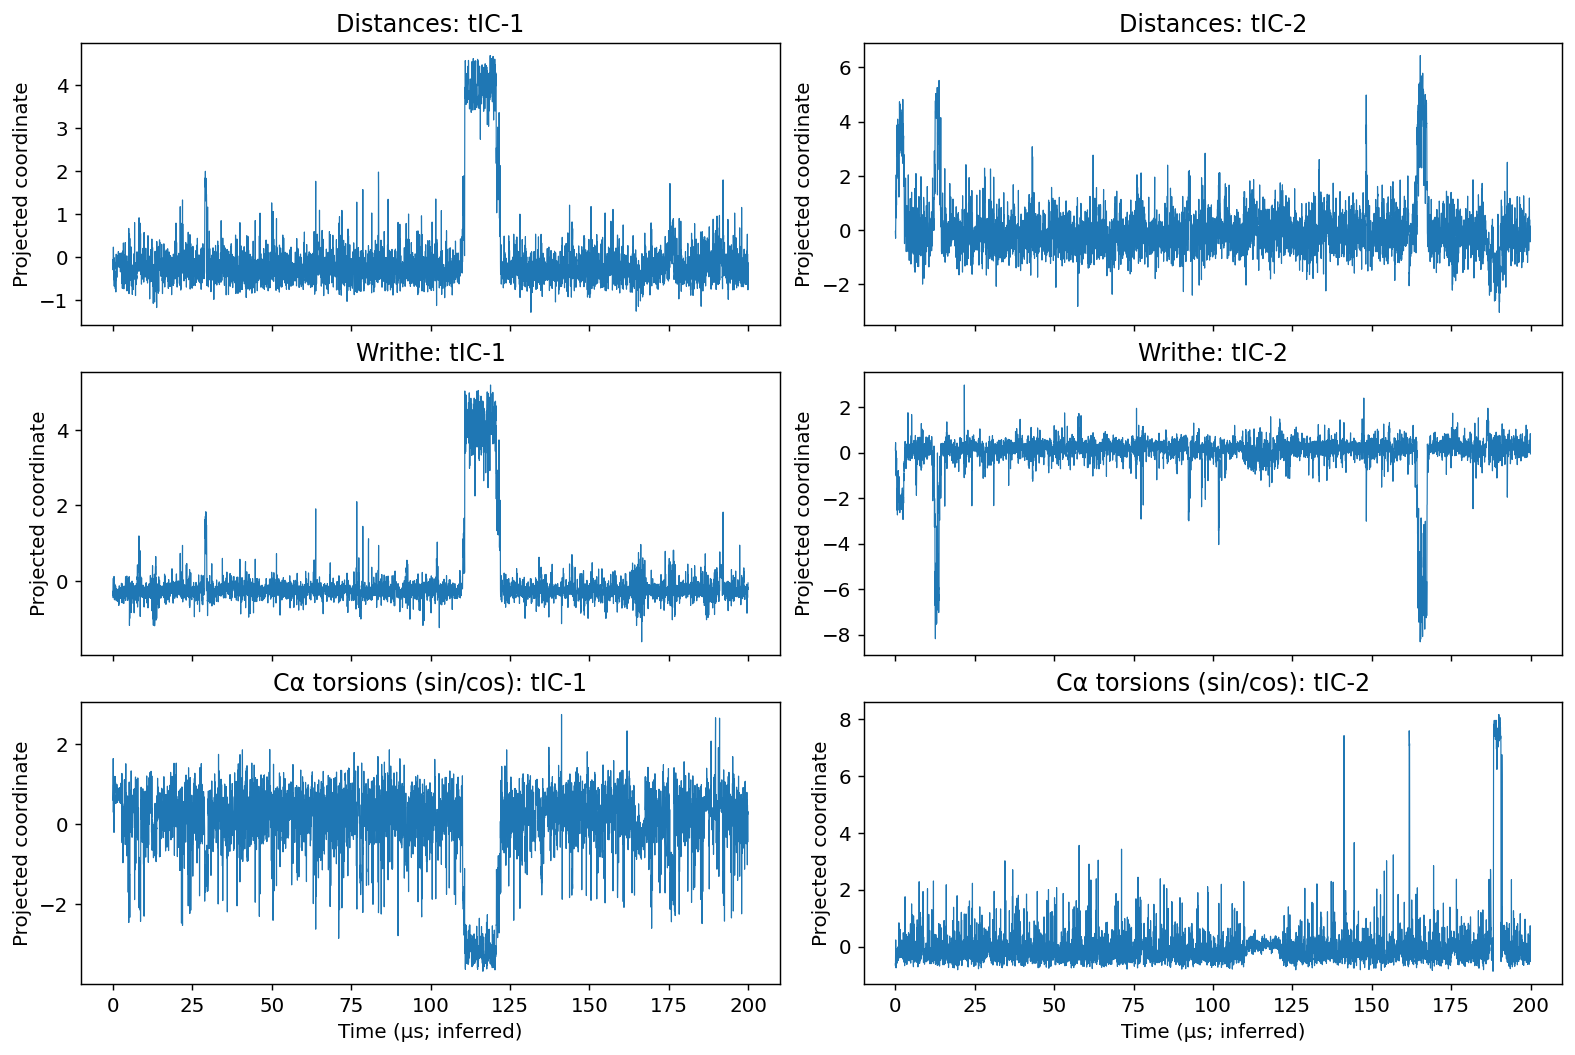

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, constrained_layout=True)
time = np.arange(len(xyz))*dt_us
for row, (name, r) in enumerate(results.items()):
    for col in range(2):
        axes[row,col].plot(time, r['tic'][:,col], lw=0.65)
        axes[row,col].set(title=f'{name}: tIC-{col+1}', ylabel='Projected coordinate')
for ax in axes[-1]: ax.set_xlabel('Time (μs; inferred)')
plt.show()


## 5. Measure autocorrelation directly from the projections
These are full-trajectory, mean-subtracted autocorrelation estimates, normalized by the full-trajectory variance. They are not forced to follow an exponential. Their values can differ slightly from the paired, symmetrized tICA eigenvalue estimator.


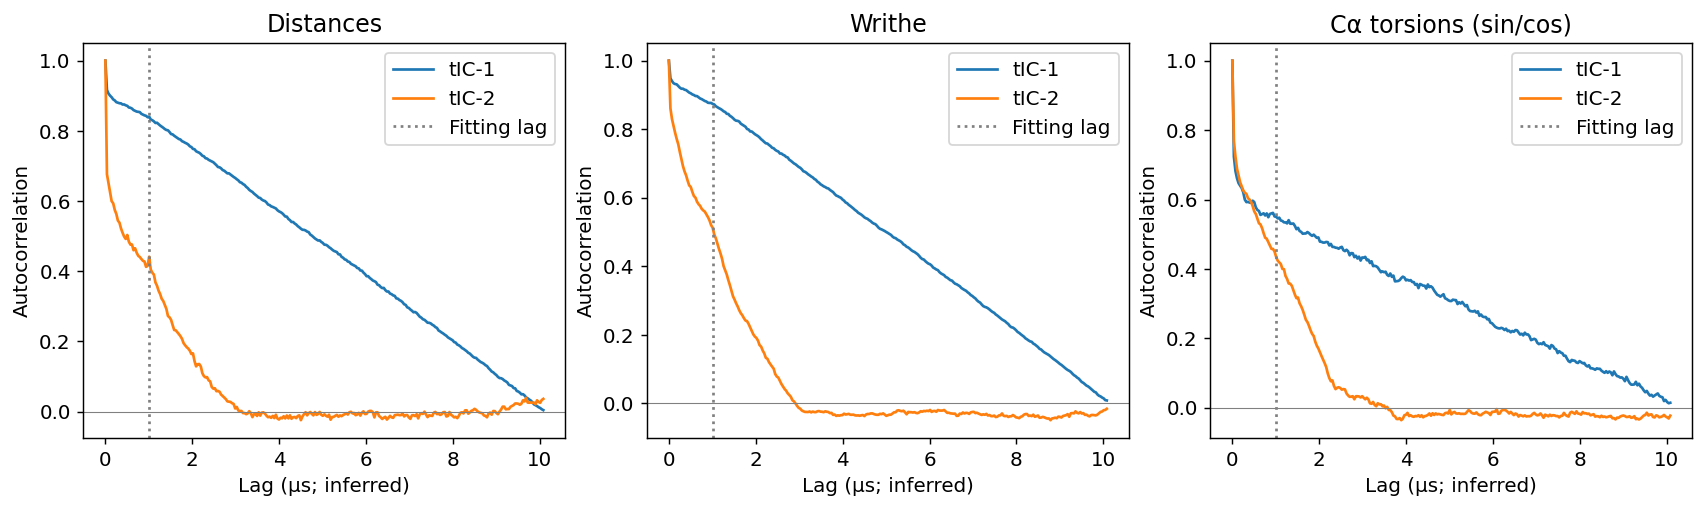

In [6]:
max_lag = 280
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, (name, r) in zip(axes, results.items()):
    for col in range(2):
        z = r['tic'][:,col] - r['tic'][:,col].mean()
        acf = np.array([np.mean(z*z)] + [np.mean(z[:-k]*z[k:]) for k in range(1,max_lag+1)]) / np.mean(z*z)
        ax.plot(np.arange(max_lag+1)*dt_us, acf, label=f'tIC-{col+1}')
    ax.axvline(lag*dt_us, color='gray', ls=':', label='Fitting lag')
    ax.axhline(0, color='gray', lw=0.6)
    ax.set(title=name, xlabel='Lag (μs; inferred)', ylabel='Autocorrelation')
    ax.legend()
plt.show()


## Structural interpretation and validation
These are exploratory instructor analyses of one trajectory. Time is inferred from the stated 200 μs duration. Splitting one trajectory tests temporal transferability, not independent replication. The three-atom observable is a **bend angle**, not a dihedral. Radius of gyration uses equal-weight Cα atoms.

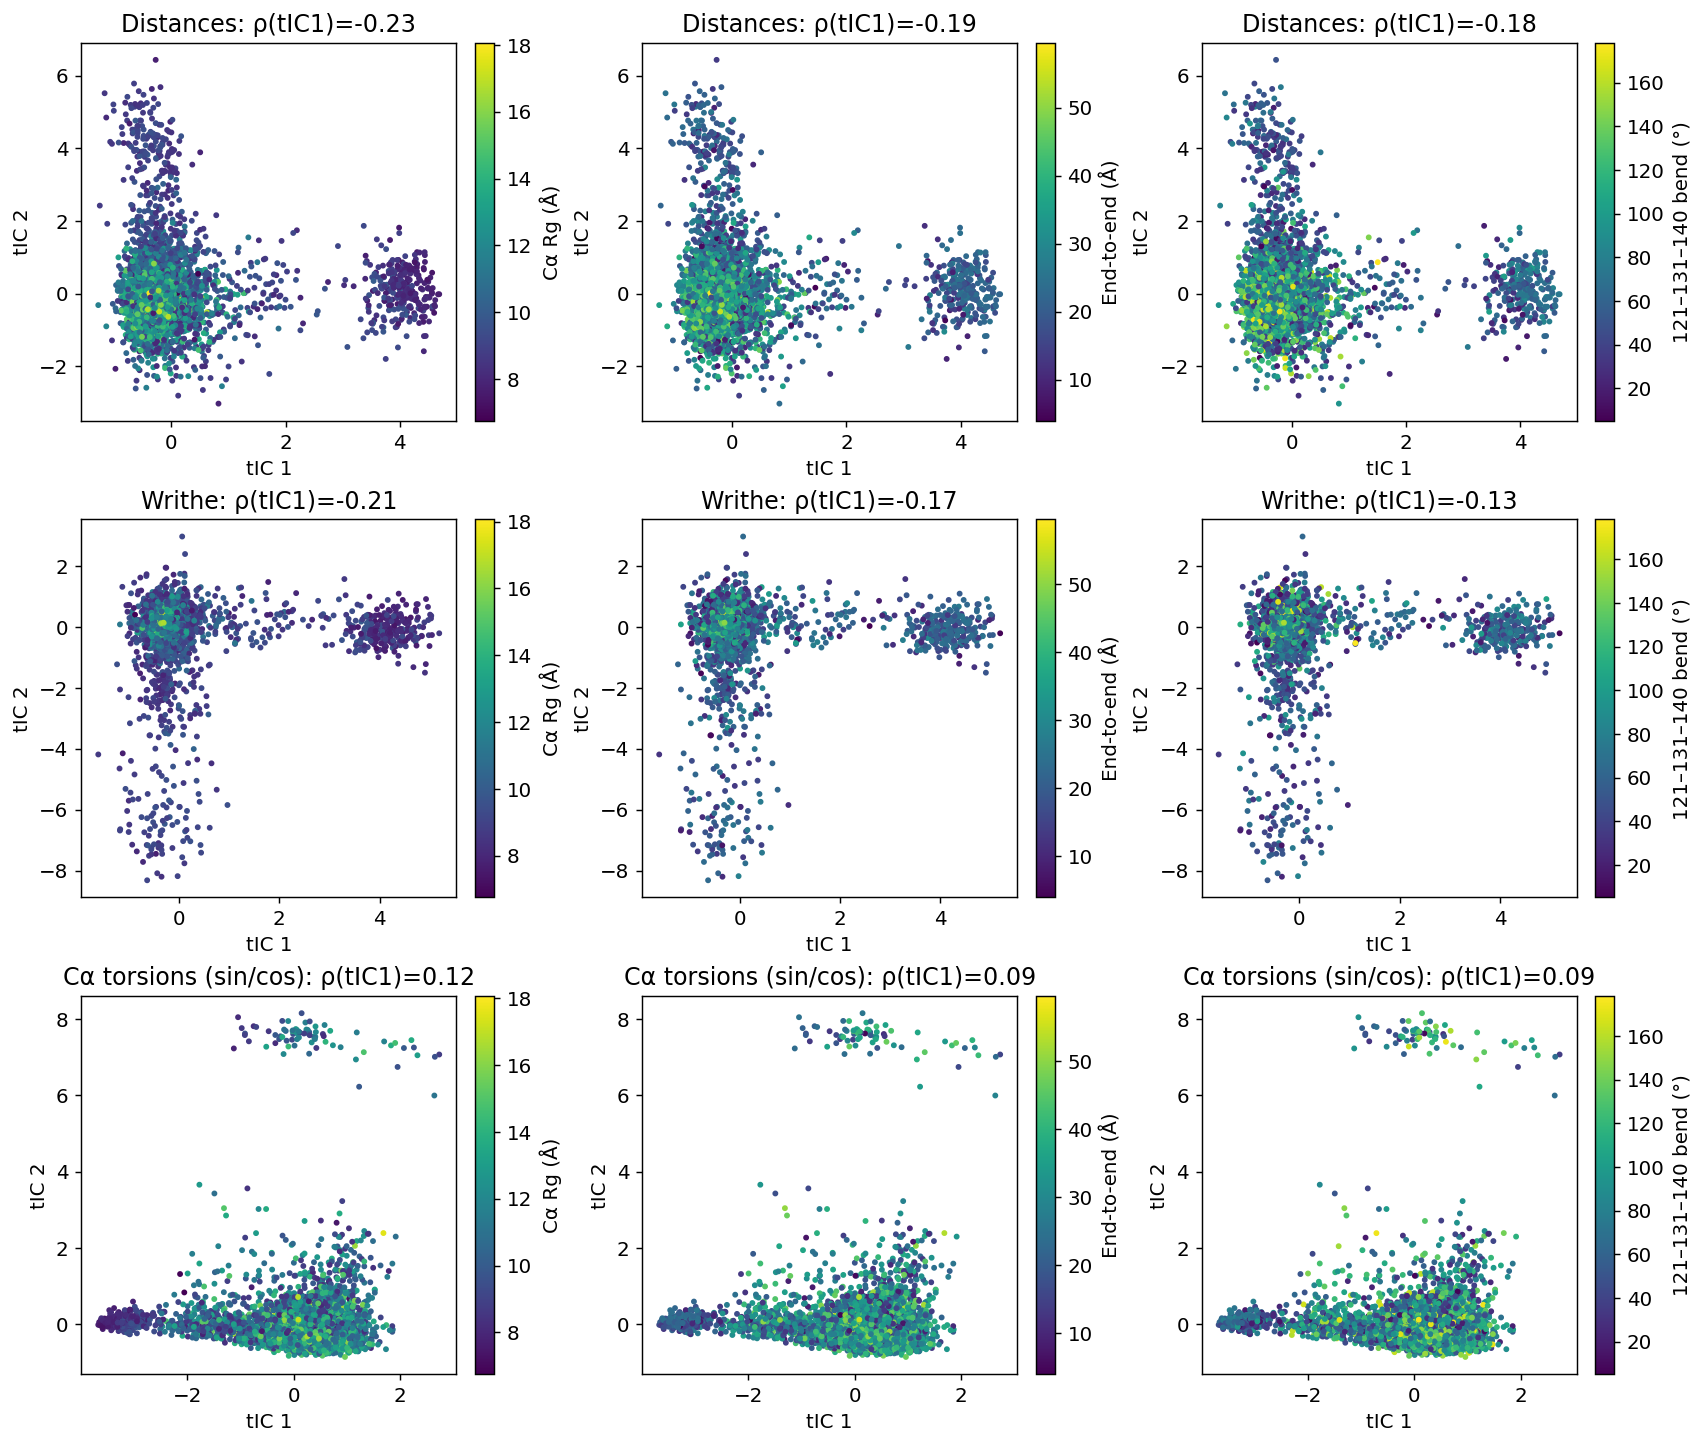

In [7]:
from scipy.stats import spearmanr
end=np.linalg.norm(xyz[:,-1]-xyz[:,0],axis=1)
a,b=xyz[:,0]-xyz[:,10],xyz[:,19]-xyz[:,10]
bend=np.degrees(np.arccos(np.clip(np.sum(a*b,axis=1)/(np.linalg.norm(a,axis=1)*np.linalg.norm(b,axis=1)),-1,1)))
observables={'Cα Rg (Å)':rg,'End-to-end (Å)':end,'121–131–140 bend (°)':bend}
fig,axs=plt.subplots(3,3,figsize=(13,11),constrained_layout=True)
for row,(name,r) in enumerate(results.items()):
 for col,(label,v) in enumerate(observables.items()):
  ax=axs[row,col];sc=ax.scatter(*r['tic'].T,c=v,s=5,cmap='viridis',rasterized=True)
  ax.set(xlabel='tIC 1',ylabel='tIC 2',title=f'{name}: ρ(tIC1)={spearmanr(r["tic"][:,0],v).statistic:.2f}')
  fig.colorbar(sc,ax=ax,label=label)
fig.savefig(data_dir/'structural_interpretation.png',dpi=180)
plt.show()


## What conformations occupy the slow coordinate?
Each structure is an actual frame nearest a selected tIC1 quantile. All Cα traces are rigidly aligned to the same reference, with identical plot limits. These are examples, not cluster averages; one structure cannot represent the diversity at a given coordinate.

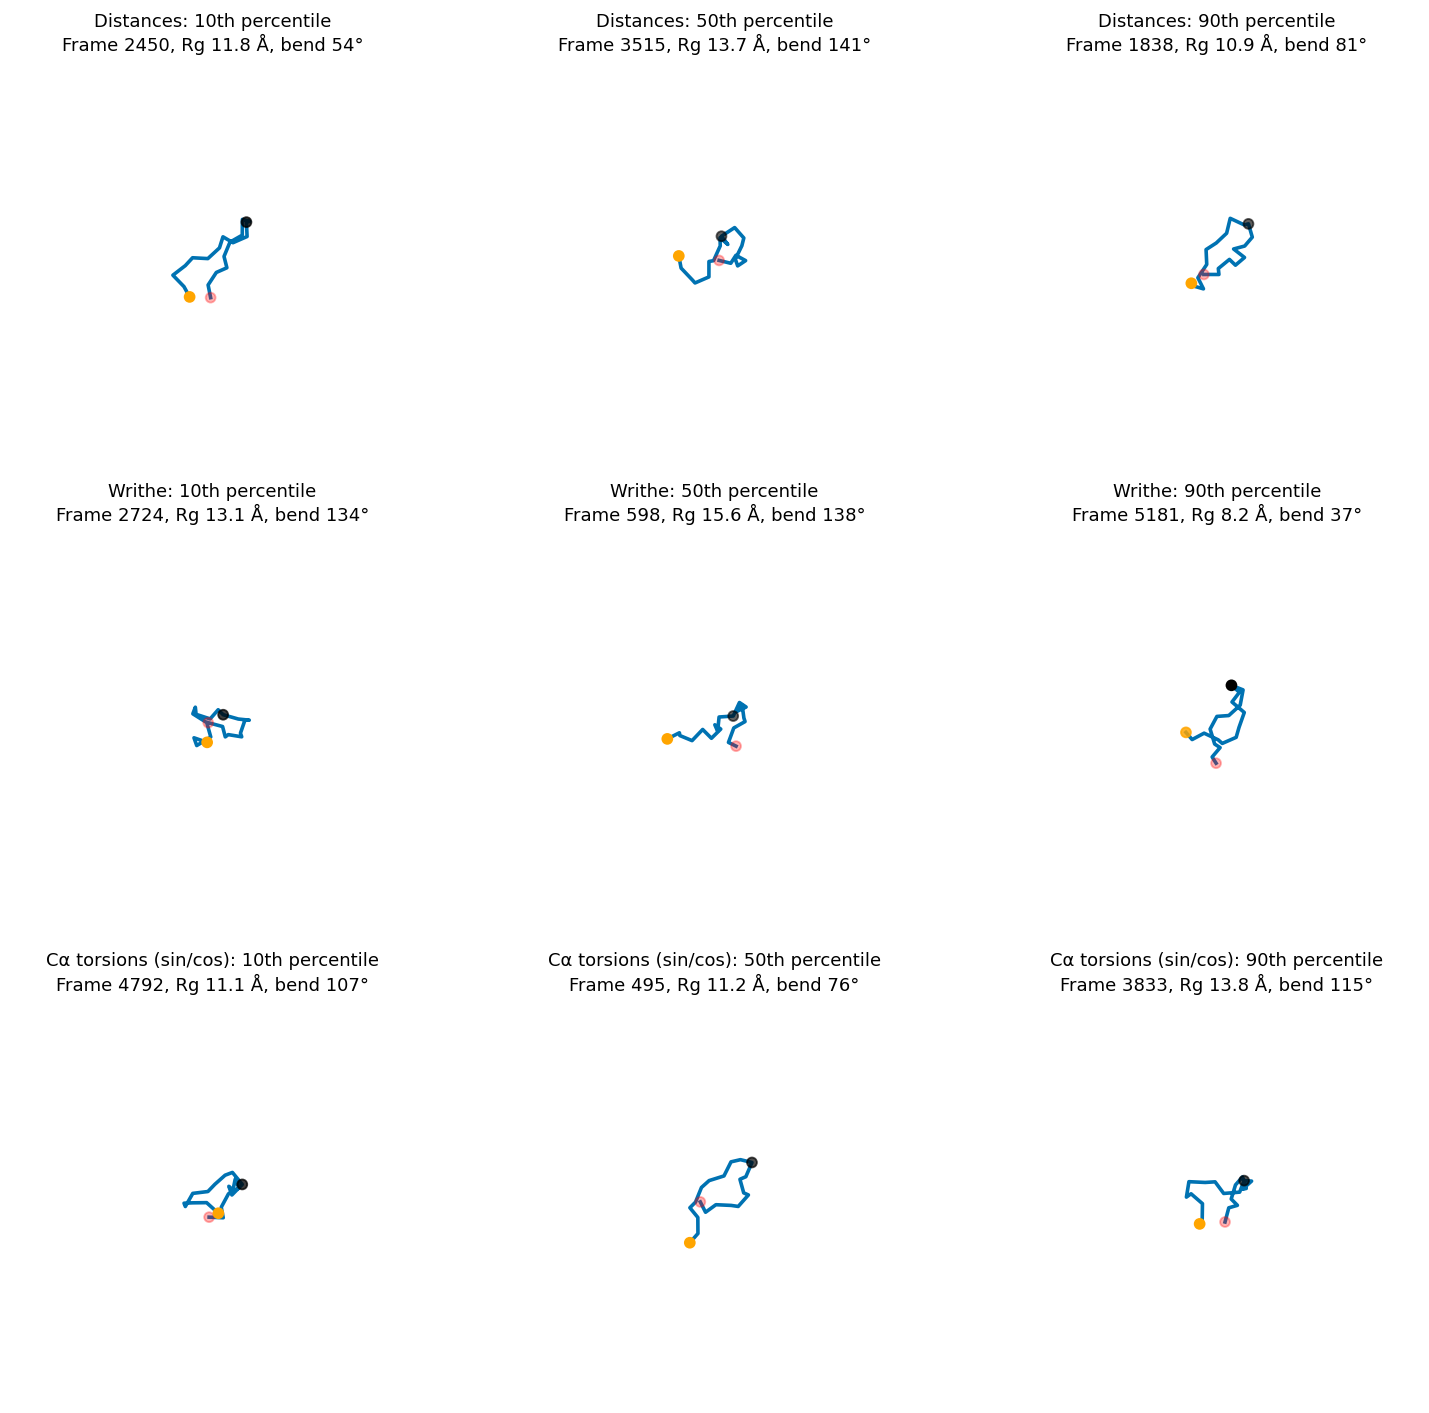

Representative frame indices: {'Distances': [2450, 3515, 1838], 'Writhe': [2724, 598, 5181], 'Cα torsions (sin/cos)': [4792, 495, 3833]}


In [8]:
ref=xyz[0]-xyz[0].mean(axis=0)
aligned=[]
for frame in xyz:
 q=frame-frame.mean(axis=0);U,S,Vt=np.linalg.svd(q.T@ref)
 D=np.eye(3);D[-1,-1]=np.linalg.det(U@Vt)
 aligned.append(q@U@D@Vt)
aligned=np.asarray(aligned)
limit=np.max(np.abs(aligned))*1.03
fig=plt.figure(figsize=(12,11));representatives={}
for row,(name,r) in enumerate(results.items()):
 ids=[int(np.argmin(abs(r['tic'][:,0]-np.quantile(r['tic'][:,0],q)))) for q in [.1,.5,.9]]
 representatives[name]=ids
 for col,idx in enumerate(ids):
  ax=fig.add_subplot(3,3,row*3+col+1,projection='3d');q=aligned[idx]
  ax.plot(*q.T,color='#0072B2',lw=2);ax.scatter(*q[[0,10,19]].T,c=['orange','black','red'],s=30)
  ax.set(xlim=(-limit,limit),ylim=(-limit,limit),zlim=(-limit,limit))
  ax.set_box_aspect((1,1,1));ax.set_axis_off()
  ax.set_title(f'{name}: {10+40*col}th percentile\nFrame {idx}, Rg {rg[idx]:.1f} Å, bend {bend[idx]:.0f}°',fontsize=10)
fig.tight_layout();fig.savefig(data_dir/'representative_structures.png',dpi=180);plt.show()
print('Representative frame indices:',representatives)


## Does the slow signal transfer across trajectory halves?
Fit reversible tICA using paired, pooled centering and symmetric lagged covariance. Retain covariance directions above 10⁻⁶ of the largest eigenvalue. For each direction learned in one half, measure its normalized lagged correlation in the other half, without refitting the direction. Both halves use the same lag and the same two-mode comparison. Eigenvector signs are arbitrary.

The held-out quantity below is a correlation diagnostic, not a cross-validated VAMP-2 score. Large fit–test differences warn against interpreting a fitted slow timescale as established kinetics.

Distances lag 28: fitted → held-out correlations
[0.542 0.362] → [0.08  0.159]
[0.891 0.56 ] → [0.004 0.152]


Writhe lag 28: fitted → held-out correlations
[0.566 0.405] → [0.171 0.407]
[0.899 0.618] → [-0.031  0.244]


Cα torsions (sin/cos) lag 28: fitted → held-out correlations
[0.225 0.151] → [ 0.05  -0.019]
[0.695 0.496] → [ 0.014 -0.05 ]


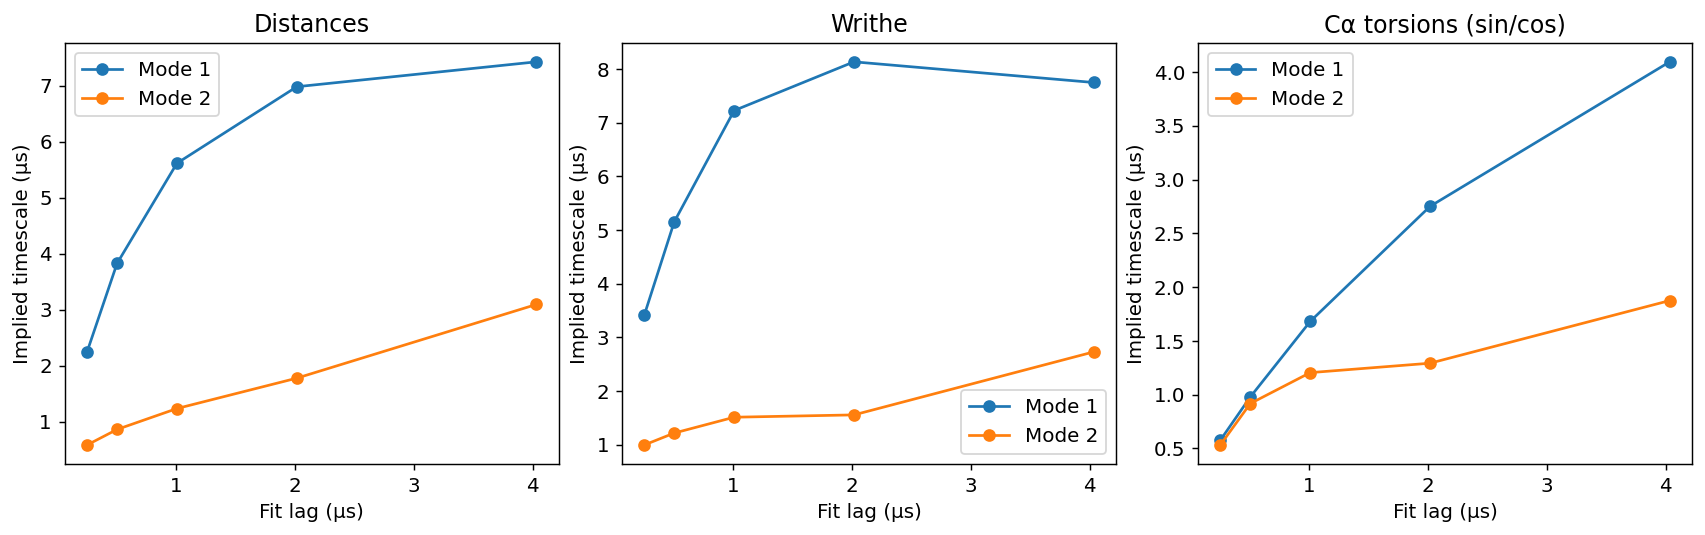

Candidate selected by weaker-half mode-1 correlation: Cα torsions (sin/cos) {'Distances': 0.004499796542927237, 'Writhe': -0.030839662818139626, 'Cα torsions (sin/cos)': 0.013725560512791064}


In [9]:
def fit_tica(F,L,ncomp=2):
 F=np.asarray(F,dtype=float);X,Y=F[:-L],F[L:]
 mean=(X.mean(0)+Y.mean(0))/2;X=X-mean;Y=Y-mean
 C0=(X.T@X+Y.T@Y)/(2*len(X));C1=(X.T@Y+Y.T@X)/(2*len(X))
 d,V=eigh(C0);keep=d>d.max()*1e-6;W=V[:,keep]/np.sqrt(d[keep])
 lam,A=eigh(W.T@C1@W);order=np.argsort(lam)[::-1][:ncomp]
 weights=W@A[:,order]
 assert np.allclose(weights.T@C0@weights,np.eye(ncomp),atol=1e-5)
 return lam[order],weights,mean

def test_corr(F,W,L):
 z=F@W;X,Y=z[:-L],z[L:];m=(X.mean(0)+Y.mean(0))/2;X=X-m;Y=Y-m
 return 2*np.sum(X*Y,axis=0)/np.sum(X*X+Y*Y,axis=0)

lags=[7,14,28,56,112];half=len(xyz)//2;validation={};ranking={}
fig,axs=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for ax,(name,F) in zip(axs,features.items()):
 values=[]
 for L in lags:
  lam,W,m=fit_tica(F,L)
  ts=np.where((lam>0)&(lam<1),-L*dt_us/np.log(lam),np.nan)
  values.append(ts)
  for train,test in [(F[:half],F[half:]),(F[half:],F[:half])]:
   fitted,W,m=fit_tica(train,L);held=test_corr(test,W,L)
   validation.setdefault(name,[]).append((L,fitted.tolist(),held.tolist()))
 values=np.array(values)
 for j in range(2):ax.plot(np.array(lags)*dt_us,values[:,j],'o-',label=f'Mode {j+1}')
 ax.set(title=name,xlabel='Fit lag (μs)',ylabel='Implied timescale (μs)');ax.legend()
 # Rank conservatively by the weaker temporal split for mode 1 at 28 frames.
 rows=[r for r in validation[name] if r[0]==28]
 ranking[name]=min(r[2][0] for r in rows)
 print(name, 'lag 28: fitted → held-out correlations')
 for _,fit,held in rows: print(np.round(fit,3),'→',np.round(held,3))
fig.savefig(data_dir/'lag_dependence.png',dpi=180);plt.show()
best=max(ranking,key=ranking.get)
print('Candidate selected by weaker-half mode-1 correlation:',best,ranking)


## Try a small MSM and test longer-time predictions
Cluster the selected feature set's first two tICs into 2–4 states. A simple reversible estimator symmetrizes transition counts, then normalizes each row. This is a count-symmetrization estimator, not a reversible maximum-likelihood fit. No transitions cross a trajectory boundary.

Compare repeated predictions T(τ)ᵏ with transition probabilities **counted directly at kτ**. The full-data check is internal consistency. The held-out check fixes both projection and cluster centers from the first half and compares first-half predictions with second-half counts. Diagonals are return probabilities, allowing departure and return. Missing originating-state counts are reported as NaN, never filled with invented transitions.

2 states, lag 28 (1.01 μs): held-out CK mean absolute error 0.042; train occupancy [1476 1301]; test [1347 1431]
3 states, lag 28 (1.01 μs): held-out CK mean absolute error 0.033; train occupancy [1115  711  951]; test [ 974  722 1082]
4 states, lag 28 (1.01 μs): held-out CK mean absolute error 0.023; train occupancy [612 565 656 944]; test [537 587 750 904]
2 states, lag 56 (2.02 μs): held-out CK mean absolute error 0.015; train occupancy [1434 1343]; test [1439 1339]
3 states, lag 56 (2.02 μs): held-out CK mean absolute error 0.059; train occupancy [ 862  905 1010]; test [ 687  854 1237]
4 states, lag 56 (2.02 μs): held-out CK mean absolute error 0.045; train occupancy [686 601 660 830]; test [ 572  490  633 1083]
2 states, lag 112 (4.03 μs): held-out CK mean absolute error 0.027; train occupancy [1468 1309]; test [1349 1429]
3 states, lag 112 (4.03 μs): held-out CK mean absolute error 0.030; train occupancy [1045  833  899]; test [ 904  807 1067]
4 states, lag 112 (4.03 μs): held-ou

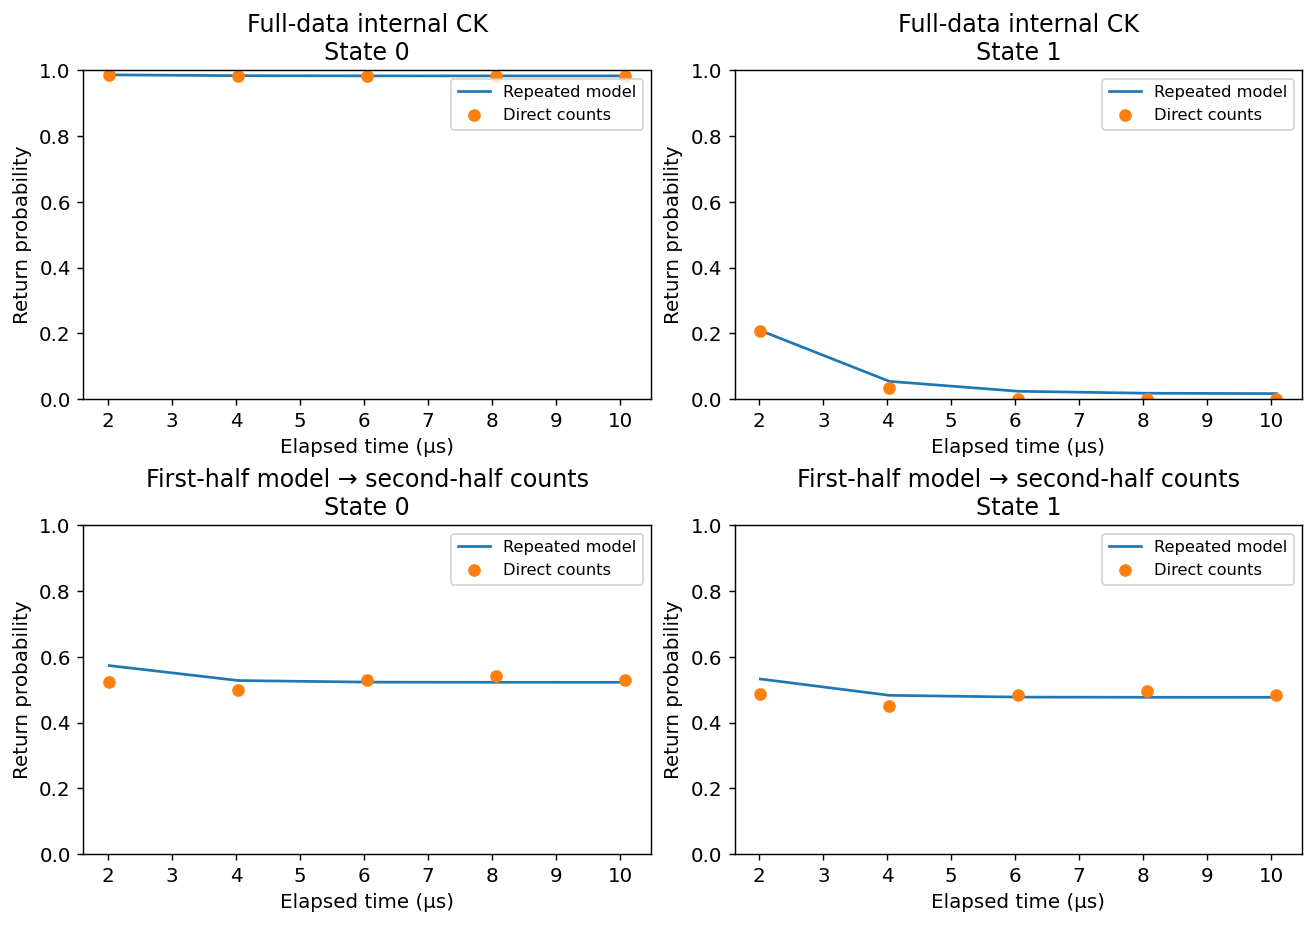

State 0 frames 5464 mean Rg/end/bend: [11.78, 31.21, 91.99]
State 1 frames 91 mean Rg/end/bend: [10.71, 28.02, 87.51]


/var/folders/52/0zs78rhj0359gt7k_n9mgvym0000gp/T/ipykernel_47031/2961628456.py:57: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[2].boxplot([bend[labels==s] for s in range(K)],labels=[str(s) for s in range(K)]);axs[2].set(xlabel='State',ylabel='Bend angle (°)')


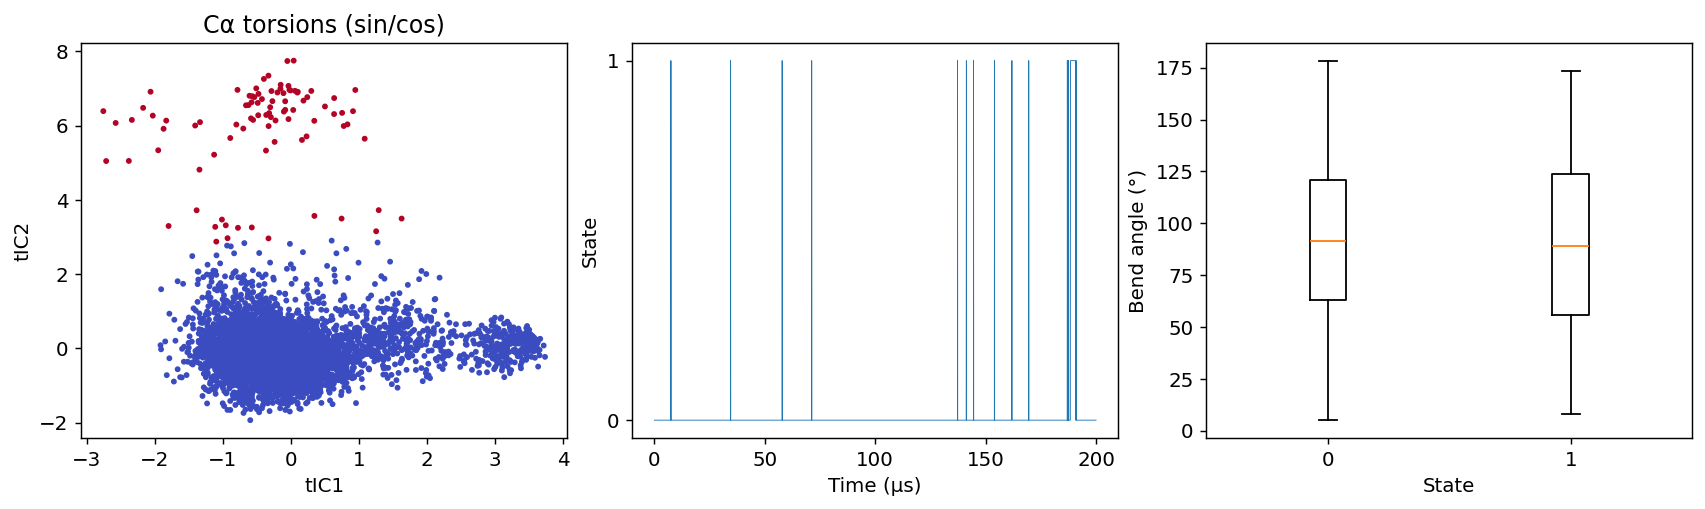

6417

In [10]:
from scipy.cluster.vq import kmeans2, vq

def counts(labels,L,K):
 return np.bincount(labels[:-L]*K+labels[L:],minlength=K*K).reshape(K,K).astype(float)
def transition(labels,L,K,reversible=False):
 C=counts(labels,L,K)
 if reversible:C=(C+C.T)/2
 den=C.sum(1)
 return np.divide(C,den[:,None],out=np.full_like(C,np.nan),where=den[:,None]>0),C

def ck_error(labels,T,L,K):
 errors=[]
 for k in [2,3,4,5]:
  direct,_=transition(labels,k*L,K)
  errors.append(np.nanmean(abs(direct-np.linalg.matrix_power(T,k))))
 return float(np.mean(errors))
F=features[best];msm_trials=[]
for L in [28,56,112]:
 lam,W,m=fit_tica(F[:half],L);train=(F[:half]-m)@W;test=(F[half:]-m)@W
 for K in [2,3,4]:
  centers,lab=kmeans2(train,K,minit='++',seed=31,iter=100)
  held=vq(test,centers)[0]
  T,C=transition(lab,L,K,True)
  if not np.isfinite(T).all():continue
  error=ck_error(held,T,L,K)
  msm_trials.append((error,L,K))
  print(f'{K} states, lag {L} ({L*dt_us:.2f} μs): held-out CK mean absolute error {error:.3f}; train occupancy {np.bincount(lab,minlength=K)}; test {np.bincount(held,minlength=K)}')
# Prefer the simplest model; choose its lag using the exploratory held-out diagnostic.
candidates=[r for r in msm_trials if r[2]==2]
error,L,K=min(candidates)
print('Illustrative model:',best,K,'states; lag',L,'frames; exploratory selection, not independent validation')
lam,W,m=fit_tica(F[:half],L);centers,trainlab=kmeans2((F[:half]-m)@W,K,minit='++',seed=31,iter=100)
heldlab=vq((F[half:]-m)@W,centers)[0];Ttrain,Ctrain=transition(trainlab,L,K,True)
# Full-data model at the selected settings, kept distinct from the held-out model.
lam,W,m=fit_tica(F,L);projection=(F-m)@W
centers,labels=kmeans2(projection,K,minit='++',seed=31,iter=100)
T,C=transition(labels,L,K,True);pi=C.sum(1)/C.sum()
assert np.allclose(T.sum(1),1)
assert np.allclose(pi[:,None]*T,(pi[:,None]*T).T)
evals=np.sort(np.linalg.eigvals(T).real)[::-1]
print('Full-data T:',T,'stationary populations:',pi,'eigenvalues:',evals)
print('Adjacent-frame state switches:',np.count_nonzero(np.diff(labels)))
print('Full-data implied relaxation time (μs):',-L*dt_us/np.log(evals[1]) if 0<evals[1]<1 else np.nan)
fig,axs=plt.subplots(2,K,figsize=(10,7),squeeze=False,constrained_layout=True)
for row,(labs,model,title) in enumerate([(labels,T,'Full-data internal CK'),(heldlab,Ttrain,'First-half model → second-half counts')]):
 for s in range(K):
  ks=np.arange(1,6);direct=[transition(labs,int(k*L),K)[0][s,s] for k in ks]
  pred=[np.linalg.matrix_power(model,int(k))[s,s] for k in ks]
  axs[row,s].plot(ks*L*dt_us,pred,'-',label='Repeated model');axs[row,s].plot(ks*L*dt_us,direct,'o',label='Direct counts')
  axs[row,s].set(title=f'{title}\nState {s}',xlabel='Elapsed time (μs)',ylabel='Return probability',ylim=(0,1));axs[row,s].legend(fontsize=9)
fig.savefig(data_dir/'msm_ck.png',dpi=180);plt.show()
fig,axs=plt.subplots(1,3,figsize=(13,3.8),constrained_layout=True)
axs[0].scatter(*projection.T,c=labels,s=5,cmap='coolwarm');axs[0].set(xlabel='tIC1',ylabel='tIC2',title=best)
axs[1].plot(np.arange(len(labels))*dt_us,labels,lw=.5);axs[1].set(xlabel='Time (μs)',ylabel='State',yticks=range(K))
for s in range(K):
 print('State',s,'frames',sum(labels==s),'mean Rg/end/bend:',[round(v[labels==s].mean(),2) for v in observables.values()])
axs[2].boxplot([bend[labels==s] for s in range(K)],labels=[str(s) for s in range(K)]);axs[2].set(xlabel='State',ylabel='Bend angle (°)')
fig.savefig(data_dir/'msm_states.png',dpi=180);plt.show()
import json
summary={'ranking':ranking,'selected_features':best,'lag_frames':L,'n_states':K,'heldout_ck_mae':error,'transition_matrix':T.tolist(),'stationary':pi.tolist(),'eigenvalues':evals.tolist(),'validation':validation}
(data_dir/'analysis_summary.json').write_text(json.dumps(summary,indent=2))


## Interpretation and limitations

- Full-trajectory fits show apparent slow timescales, but the leading projections change substantially between trajectory halves. At lag 28 frames, leading-mode held-out correlations are close to zero for several descriptors. Do not interpret the full-data eigenvalues alone as validated kinetics.
- The feature selection below chooses the least unstable leading mode by a simple held-out criterion; it does **not** identify a convincingly validated feature set. Shorter-lag writhe modes show more retained correlation, but mode ordering and interpretation require further work.
- The selected two-state model has a small held-out CK discrepancy, yet refitting on the full trajectory produces one rare state (~1.7% population), unlike the approximately balanced training split. State labels in the full-refit and held-out CK panels therefore refer to different fitted partitions.
- CK agreement can occur after rapid mixing. It does not by itself demonstrate metastability, stable states, or reliable slow kinetics. The reported full-refit relaxation time is a model estimate, not a validated physical conclusion.
- Feature/model selection and evaluation reuse the held-out half. These are exploratory diagnostics, not an unbiased final test. Uncertainty intervals and an independent trajectory are needed before stronger claims.
- The 200 μs duration is user-supplied. Recheck saved-frame timing before assigning physical timescales. Cα radius of gyration uses equal atom weights.

**Teaching takeaway:** compare feature representations, inspect the structures they separate, and test stability across time blocks. A clean-looking projection or CK plot is insufficient evidence for a reliable MSM.